# pixel2dag · Notebook 03 — El dataset

**Objetivo:** pasar de "un paciente con su imagen" a **miles de pacientes** guardados en disco y listos para entrenar modelos en el notebook 04.

**Aprenderás:**
- a medir cuánto tarda tu código y a acelerarlo (×4);
- `pandas`, desde cero, para trabajar con la tabla de pacientes;
- a guardar y cargar datos ocupando 4 veces menos espacio;
- a crear **"mundos" de test** en los que la relación entre hospital y enfermedad cambia. Esa es la clave para detectar atajos.

**Duración:** unos 60 minutos. **Necesitas además:** `pip install pandas`.

Las celdas son del mismo tipo que en los notebooks anteriores: 🔍 Ejemplo, 🤔 Predice, ✏️ Ejercicio y ✅ Comprobación.

### Código de los notebooks 01 y 02

Esta es la versión resuelta, para que el notebook funcione por sí solo.

In [23]:
import random, math, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- notebook 01 ----------
def dado(semilla, variable):
    return random.Random(f"{semilla}-{variable}")

def lanzar_monedas(rng, n, p):
    return sum(rng.random() < p for _ in range(n))

def sigmoide(x):
    return 1 / (1 + math.exp(-x))

def prob_gravedad(edad, hospital):
    return sigmoide(-1 + 0.05 * (edad - 60) + 1.5 * (hospital == "A"))

PROB_MA = [0.0, 0.075, 0.2, 0.375, 0.625]
PROB_EX = [0.0, 0.0, 0.1, 0.25, 0.5]

def simular_paciente(semilla, do=None):
    do = do or {}
    hospital = do["hospital"] if "hospital" in do else ("A" if dado(semilla, "hospital").random() < 0.5 else "B")
    edad = do["edad"] if "edad" in do else dado(semilla, "edad").gauss(60, 10)
    gravedad = do["gravedad"] if "gravedad" in do else lanzar_monedas(dado(semilla, "gravedad"), 4, prob_gravedad(edad, hospital))
    n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
    n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])
    return {"semilla": semilla, "hospital": hospital, "edad": edad, "gravedad": gravedad,
            "n_ma": n_ma, "n_ex": n_ex, "referable": int(gravedad >= 2)}

# ---------- notebook 02 ----------
IMG = 64
C = (IMG - 1) / 2
R = IMG * 0.46
YY, XX = np.mgrid[0:IMG, 0:IMG]
D = np.sqrt((YY - C) ** 2 + (XX - C) ** 2)
MASCARA = D <= R
factor = 1 - 0.35 * (D / R) ** 2

def pintar_mancha(img, cy, cx, radio, color, alpha=1.0):
    w = alpha * np.exp(-((YY - cy) ** 2 + (XX - cx) ** 2) / (2 * radio ** 2))
    return (1 - w[..., None]) * img + w[..., None] * np.array(color)

def dibujar_vasos(img, semilla, ny, nx):
    rng = dado(semilla, "vasos")
    for _ in range(4):
        y, x = ny, nx
        angulo = rng.uniform(0, 2 * math.pi)
        grosor = 1.2
        for paso in range(60):
            angulo += rng.gauss(0, 0.18)
            y += math.sin(angulo)
            x += math.cos(angulo)
            if math.hypot(y - C, x - C) > R:
                break
            img = pintar_mancha(img, y, x, grosor, [0.55, 0.08, 0.05], 0.6)
            grosor = max(0.5, grosor * 0.99)
    return img

def fondo_de_ojo(semilla):
    lado = dado(semilla, "lado").choice([-1, 1])
    ny, nx = 32, C + lado * 16
    img = np.zeros((IMG, IMG, 3))
    img[MASCARA] = [0.8, 0.35, 0.15]
    img = img * factor[..., None]
    img = pintar_mancha(img, ny, nx, 4, [0.98, 0.85, 0.55], 0.95)
    img = dibujar_vasos(img, semilla, ny, nx)
    return img

def posicion_en_disco(rng):
    distancia = R * 0.9 * math.sqrt(rng.random())
    angulo = rng.uniform(0, 2 * math.pi)
    return C + distancia * math.sin(angulo), C + distancia * math.cos(angulo)

def dibujar_microaneurismas(img, semilla, n_ma):
    rng = dado(semilla, "pos_ma")
    for i in range(n_ma):
        y, x = posicion_en_disco(rng)
        img = pintar_mancha(img, y, x, 0.8, [0.35, 0, 0], 0.95)
    return img

def dibujar_exudados(img, semilla, n_ex):
    rng = dado(semilla, "pos_ex")
    for i in range(n_ex):
        y, x = posicion_en_disco(rng)
        radio = rng.uniform(0.9, 1.8)
        img = pintar_mancha(img, y, x, radio, [1.0, 0.92, 0.35], 0.9)
    return img

def efecto_escaner(img, hospital, semilla):
    rng_np = np.random.default_rng(dado(semilla, "ruido").randrange(2**32))
    if hospital == "A":
        img = img + rng_np.normal(0, 0.02, img.shape)
        img[2:7, 2:7] = 1.0
    else:
        img = img * 0.8 * factor[..., None]
        img = img + rng_np.normal(0, 0.05, img.shape)
    return np.clip(img, 0, 1)

def renderizar(paciente):
    s = paciente["semilla"]
    img = fondo_de_ojo(s)
    img = dibujar_microaneurismas(img, s, paciente["n_ma"])
    img = dibujar_exudados(img, s, paciente["n_ex"])
    img = efecto_escaner(img, paciente["hospital"], s)
    return img

pintar_mancha_lenta = pintar_mancha   # guardamos la versión original para compararla luego
print("✅ Código cargado")

✅ Código cargado


---
## Parte 1 · ¿Cuánto tarda?

Antes de generar miles de imágenes conviene saber cuánto tardará.

### 🔍 Ejemplo: medir el tiempo

`time.perf_counter()` devuelve un reloj en segundos. Se lee antes y después, y se resta.

In [24]:
t0 = time.perf_counter()
suma = sum(i * i for i in range(1_000_000))
t1 = time.perf_counter()
print(f"Ha tardado {t1 - t0:.3f} segundos")

Ha tardado 0.118 segundos


### ✏️ Ejercicio 1.1

Mide cuánto tarda en renderizar **20 pacientes** (semillas de 0 a 19) y guarda en `ms_por_imagen` los **milisegundos por imagen**.

<details><summary>▶ Pista</summary>

Primero crea la lista de pacientes **fuera** de la medición, porque solo queremos medir el renderizado. Luego: `t0`, un bucle (o una lista por comprensión) con `renderizar`, `t1`, y `(t1 - t0) / 20 * 1000`.
</details>

In [25]:
pacientes20 = [simular_paciente(s) for s in range(20)]
t0 =  time.perf_counter()
for p in pacientes20:
  renderizar(p)
t1 = time.perf_counter()
ms_por_imagen = (t1- t0)/20*1000
print(f"{ms_por_imagen:.1f} ms por imagen")

30.2 ms por imagen


In [26]:
# ✅ Comprobación
assert isinstance(ms_por_imagen, float) and ms_por_imagen > 0.1, "ms_por_imagen debería ser un número positivo"
print(f"✅ Correcto. Para 6000 imágenes (entrenamiento + 3 tests): unos {ms_por_imagen * 6000 / 1000:.0f} segundos")

✅ Correcto. Para 6000 imágenes (entrenamiento + 3 tests): unos 181 segundos


### 🔍 ¿Dónde se va el tiempo?

Contemos cuántas veces se llama a `pintar_mancha` al dibujar **un** paciente. El truco de abajo envuelve la función en otra que cuenta las llamadas; no hace falta que lo entiendas en detalle.

In [27]:
llamadas = 0
def contar(*args, **kwargs):
    global llamadas
    llamadas += 1
    return pintar_mancha_lenta(*args, **kwargs)

pintar_mancha = contar
renderizar(simular_paciente(17))
pintar_mancha = pintar_mancha_lenta
print("Llamadas a pintar_mancha para un paciente:", llamadas)

Llamadas a pintar_mancha para un paciente: 132


Son más de cien llamadas, casi todas de los vasos. Cada una calcula `w` para **los 4096 píxeles** de la imagen, cuando una mancha de radio 1 solo afecta a unos pocos píxeles: más allá de 3 radios, `w` es prácticamente 0.

💡 **Idea:** calcular solo en una **ventana** pequeña alrededor de la mancha.

### 🔍 Ejemplo: modificar solo un trozo de la matriz

Con *slicing* podemos leer y escribir una sub-matriz. `YY[y0:y1, x0:x1]` son las filas de la ventana, y lo mismo con `XX`.

In [28]:
m = np.zeros((6, 6))
ventana = m[1:4, 2:5]             # una vista de 3x3
m[1:4, 2:5] = ventana + 7         # escribimos solo en la ventana
print(m)

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 7. 7. 7. 0.]
 [0. 0. 7. 7. 7. 0.]
 [0. 0. 7. 7. 7. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


### ✏️ Ejercicio 1.2 · `pintar_mancha_rapida`

Te damos el cálculo de los límites de la ventana: 3 radios alrededor del centro, sin salirse de la imagen. Tienes que:
1. Calcular `w` igual que antes, pero con `YY[y0:y1, x0:x1]` y `XX[y0:y1, x0:x1]` en lugar de `YY` y `XX`.
2. Escribir la mezcla solo en la ventana: `img[y0:y1, x0:x1] = (1 - w[..., None]) * img[y0:y1, x0:x1] + ...`

La primera línea, `img = img.copy()`, garantiza que no modificas la imagen original.

In [29]:
def pintar_mancha_rapida(img, cy, cx, radio, color, alpha=1.0):
    #caja delimitadora
    m = int(math.ceil(3 * radio)) + 1
    y0, y1 = max(0, int(cy) - m), min(IMG, int(cy) + m + 1)
    x0, x1 = max(0, int(cx) - m), min(IMG, int(cx) + m + 1)
    img = img.copy()

    #si queda fuera de la caja devolvemos la original
    if y0 >= y1 or x0 >= x1:
        return img
    #peso de la mancha dependiendo de la distancia
    w = alpha * np.exp(-((YY[y0:y1, x0:x1] - cy) ** 2 + (XX[y0:y1, x0:x1] - cx) ** 2) / (2 * radio ** 2))

    #color
    img[y0:y1, x0:x1] = (1 - w[..., None]) * img[y0:y1, x0:x1] + w[..., None] * np.array(color)
    return img

In [30]:
# ✅ Comprobación
base = fondo_de_ojo(3)
copia = base.copy()
for (cy, cx, r) in [(32, 32, 1), (10, 50, 2.5), (0, 0, 1.5), (63, 20, 4)]:
    a = pintar_mancha_lenta(base, cy, cx, r, [1, 1, 0], 0.9)
    b = pintar_mancha_rapida(base, cy, cx, r, [1, 1, 0], 0.9)
    assert np.abs(a - b).max() < 0.02, f"La mancha en ({cy}, {cx}) con radio {r} no coincide con la versión lenta"
assert np.array_equal(base, copia), "No debes modificar la imagen original"
print("✅ Da (casi) el mismo resultado que la versión lenta")

✅ Da (casi) el mismo resultado que la versión lenta


### 🔍 Cambiar la versión en todo el código de golpe

Las demás funciones (`dibujar_vasos`, `dibujar_microaneurismas`...) buscan `pintar_mancha` **por su nombre** cada vez que se ejecutan. Si hacemos que ese nombre apunte a la nueva función, todas pasan a usarla automáticamente.

In [31]:
pintar_mancha = pintar_mancha_rapida

### ✏️ Ejercicio 1.3

Repite la medición del ejercicio 1.1 y guárdala en `ms_rapido`.

In [32]:
t0 = time.perf_counter()
for p in pacientes20:
  renderizar(p)
t1 = time.perf_counter()
ms_rapido = (t1- t0)/20*1000
print(f"Antes: {ms_por_imagen:.1f} ms/imagen  →  ahora: {ms_rapido:.1f} ms/imagen  (×{ms_por_imagen / ms_rapido:.1f})")

Antes: 30.2 ms/imagen  →  ahora: 6.1 ms/imagen  (×5.0)


In [33]:
# ✅ Comprobación
assert ms_rapido < ms_por_imagen, "Debería ir más rápido. ¿Has ejecutado la celda pintar_mancha = pintar_mancha_rapida?"
print("✅ ¡Más rápido! Lección: antes de optimizar, mide dónde se va el tiempo.")

✅ ¡Más rápido! Lección: antes de optimizar, mide dónde se va el tiempo.


---
## Parte 2 · Generar el dataset

### 🔍 Ejemplo: `np.stack`

Junta una lista de matrices de la misma forma en **una sola matriz** con una dimensión más. Con una lista de 5 imágenes de `(64, 64, 3)` obtienes `(5, 64, 64, 3)`.

In [34]:
lista = [np.zeros((64, 64, 3)) for _ in range(5)]
X_mini = np.stack(lista)
print("forma:", X_mini.shape)
print("imagen nº 2:", X_mini[2].shape)

forma: (5, 64, 64, 3)
imagen nº 2: (64, 64, 3)


### ✏️ Ejercicio 2.1 · `generar_dataset(semillas, do)`

1. Crea la lista de pacientes: uno por semilla, con `simular_paciente(s, do)`.
2. Renderiza cada uno y apílalos con `np.stack`. Conviértelo con `.astype(np.float32)`, que ocupa la mitad que el formato por defecto.
3. Devuelve `X, pacientes`.

In [35]:
def generar_dataset(semillas, do=None):
    pacientes = [simular_paciente(s, do) for s in semillas]
    X = np.stack([renderizar(p) for p in pacientes]).astype(np.float32)
    return X, pacientes

In [36]:
# ✅ Comprobación
X_prueba, pac_prueba = generar_dataset(range(10))
assert X_prueba.shape == (10, 64, 64, 3) and X_prueba.dtype == np.float32
assert pac_prueba[3] == simular_paciente(3)
assert np.allclose(X_prueba[3], renderizar(simular_paciente(3)), atol=1e-6)
print("✅ Correcto")

✅ Correcto


Generamos ya el conjunto de entrenamiento: 3000 pacientes con las semillas de 0 a 2999. Tardará unos segundos.

In [37]:
t0 = time.perf_counter()
X_tr, pacientes_tr = generar_dataset(range(3000))
print(f"X_tr: {X_tr.shape} en {time.perf_counter() - t0:.1f} s")

X_tr: (3000, 64, 64, 3) en 20.8 s


---
## Parte 3 · `pandas`: la tabla de pacientes

`pacientes_tr` es una lista de 3000 diccionarios, incómoda de analizar. `pandas` la convierte en una **tabla** (un `DataFrame`): una fila por paciente y una columna por variable, como una hoja de cálculo.

### 🔍 Ejemplo: lo básico de `pandas`

In [38]:
tabla_tr = pd.DataFrame(pacientes_tr)
display(tabla_tr.head())                       # las 5 primeras filas

print("Una columna:       ", tabla_tr["gravedad"].head(3).tolist())
print("Media de la edad:  ", round(tabla_tr["edad"].mean(), 1))
print("Cuántos de cada:   ", tabla_tr["hospital"].value_counts().to_dict())

solo_A = tabla_tr[tabla_tr["hospital"] == "A"]  # filtrar: como en las listas por comprensión del notebook 01
print("Pacientes de A:    ", len(solo_A))

,semilla,hospital,edad,gravedad,n_ma,n_ex,referable
0,0,A,64.761658,3,9,7,1
1,1,B,65.656793,1,4,0,0
2,2,B,50.964815,1,5,0,0
3,3,A,63.710723,1,7,0,0
4,4,A,53.283822,3,14,6,1


Una columna:        [3, 1, 1]
Media de la edad:   60.1
Cuántos de cada:    {'B': 1510, 'A': 1490}
Pacientes de A:     1490


### 🔍 Ejemplo: `groupby`, "calcula esto por grupos"

`tabla.groupby("columna_grupo")["columna"].mean()` calcula la media de `columna` **por separado para cada valor** de `columna_grupo`. Sustituye a los bucles y filtros que escribiste a mano en el notebook 01.

In [39]:
print(tabla_tr.groupby("hospital")["edad"].mean())

hospital
A    60.238801
B    60.017921
Name: edad, dtype: float64


### ✏️ Ejercicio 3.1

Guarda en `prev_por_hospital` la **fracción de referables por hospital**. Es una línea: la media de `referable` agrupando por `hospital`. Compárala con lo que calculaste a mano en el notebook 01.

In [40]:
prev_por_hospital = tabla_tr.groupby("hospital")["referable"].mean()
print(prev_por_hospital)

hospital
A    0.820134
B    0.300662
Name: referable, dtype: float64


In [41]:
# ✅ Comprobación
assert 0.75 < prev_por_hospital["A"] < 0.88 and 0.25 < prev_por_hospital["B"] < 0.4
print("✅ Correcto")

✅ Correcto


### ✏️ Ejercicio 3.2

Guarda en `ma_por_gravedad` la **media de microaneurismas para cada gravedad**.

🤔 Antes de ejecutar, predice: según `PROB_MA` y los 40 sitios, ¿qué medias deberían salir?

In [42]:
ma_por_gravedad = tabla_tr.groupby("gravedad")["n_ma"].mean()
print(ma_por_gravedad)

gravedad
0     0.000000
1     3.002404
2     8.071970
3    14.959283
4    25.144444
Name: n_ma, dtype: float64


In [43]:
# ✅ Comprobación
esperado = [40 * p for p in PROB_MA]
for g in range(5):
    assert abs(ma_por_gravedad[g] - esperado[g]) < 1.5, f"Para gravedad {g} se esperaban ≈{esperado[g]}"
print("✅ Correcto: coinciden con 40 · PROB_MA =", esperado)

✅ Correcto: coinciden con 40 · PROB_MA = [0.0, 3.0, 8.0, 15.0, 25.0]


### ✏️ Ejercicio 3.3

¿Cuántos pacientes **sanos** (gravedad 0) hay en el hospital **B**? Guárdalo en `sanos_B`.

<details><summary>▶ Pista</summary>

Para combinar dos condiciones en `pandas` se usa `&` y cada condición va entre paréntesis: `tabla[(cond1) & (cond2)]`. Luego usa `len(...)`.
</details>

In [44]:
sanos_B = len(tabla_tr[(tabla_tr["gravedad"] == 0) & (tabla_tr["hospital"] == "B")])
print(sanos_B)

457


In [45]:
# ✅ Comprobación
assert sanos_B == sum(1 for p in pacientes_tr if p["hospital"] == "B" and p["gravedad"] == 0)
print("✅ Correcto")

✅ Correcto


### 🔍 Un vistazo al dataset

`pd.crosstab` cuenta combinaciones; con `normalize="index"` da porcentajes por fila. Debajo, las primeras imágenes con sus datos.

referable,0,1
hospital,,
A,0.18,0.82
B,0.70,0.30


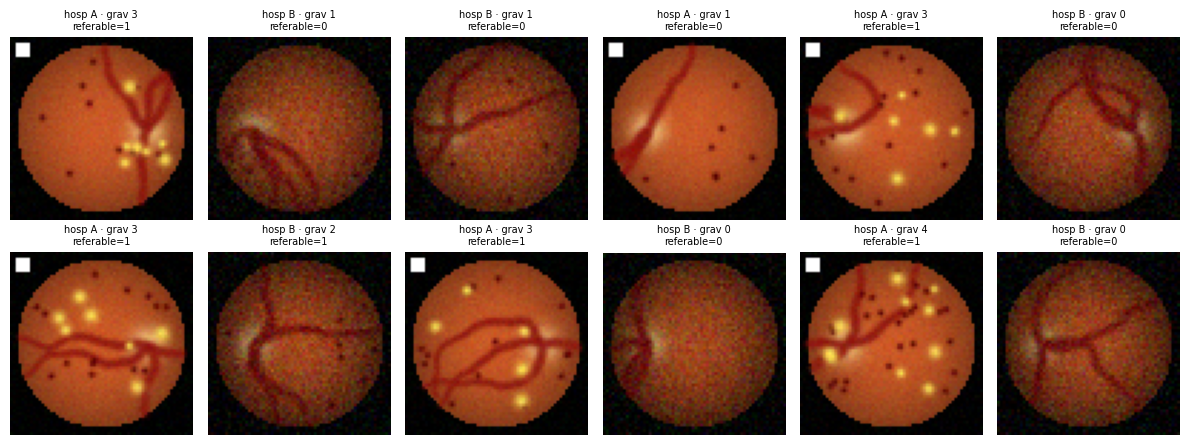

In [46]:
display(pd.crosstab(tabla_tr["hospital"], tabla_tr["referable"], normalize="index").round(2))

fig, axs = plt.subplots(2, 6, figsize=(12, 4.6))
for i, ax in enumerate(axs.ravel()):
    ax.imshow(X_tr[i]); ax.axis("off")
    fila = tabla_tr.iloc[i]          # .iloc[i] = fila número i
    ax.set_title(f"hosp {fila['hospital']} · grav {fila['gravedad']}\nreferable={fila['referable']}", fontsize=7)
plt.tight_layout(); plt.show()

---
## Parte 4 · Mundos de test

### La idea

En la vida real, un modelo se entrena con datos de unos hospitales y luego se usa en otros, donde la relación entre hospital y enfermedad puede ser distinta. Para simularlo creamos varios **"mundos"**. Todos tienen **la misma enfermedad y el mismo escáner**; solo cambia cuánto influye el hospital en la gravedad:

| Mundo | `base` | `coef_hospital_A` | Qué significa |
|---|---|---|---|
| Entrenamiento | −1.0 | 1.5 | A es centro de referencia (lo que tenías hasta ahora) |
| Sin confusión | −1.0 | 0.0 | El hospital no influye en la gravedad |
| Invertido | 0.5 | −1.5 | Ahora es **B** el que recibe los casos graves |

En el DAG, solo cambia el **mecanismo** de la flecha `hospital → gravedad`. Las flechas hacia la imagen se quedan igual.

In [47]:
MUNDO_ENTRENAMIENTO = {"base": -1.0, "coef_hospital_A": 1.5}
MUNDO_SIN_CONFUSION = {"base": -1.0, "coef_hospital_A": 0.0}
MUNDO_INVERTIDO     = {"base": 0.5,  "coef_hospital_A": -1.5}

### ✏️ Ejercicio 4.1 · `prob_gravedad` con mundo

Reescribe `prob_gravedad` para que use `mundo["base"]` en lugar de `-1` y `mundo["coef_hospital_A"]` en lugar de `1.5`. Lo demás se queda igual. Es una línea.

In [48]:
def prob_gravedad(edad, hospital, mundo=MUNDO_ENTRENAMIENTO):
    return sigmoide(mundo["base"] + mundo["coef_hospital_A"] * (hospital == "A"))

In [49]:
# ✅ Comprobación
assert abs(prob_gravedad(60, "A") - 0.622) < 0.001, "Con el mundo de entrenamiento debe dar lo mismo que antes"
assert abs(prob_gravedad(60, "A", MUNDO_SIN_CONFUSION) - prob_gravedad(60, "B", MUNDO_SIN_CONFUSION)) < 1e-9
assert prob_gravedad(60, "B", MUNDO_INVERTIDO) > prob_gravedad(60, "A", MUNDO_INVERTIDO)
print("✅ Correcto")

✅ Correcto


### 🔍 `simular_paciente` y `generar_dataset` con mundo

Solo cambia que reciben un parámetro `mundo` más y se lo pasan a `prob_gravedad`. Las líneas modificadas están marcadas con `# ←`.

In [50]:
def simular_paciente(semilla, do=None, mundo=MUNDO_ENTRENAMIENTO):                       # ←
    do = do or {}
    hospital = do["hospital"] if "hospital" in do else ("A" if dado(semilla, "hospital").random() < 0.5 else "B")
    edad = do["edad"] if "edad" in do else dado(semilla, "edad").gauss(60, 10)
    gravedad = do["gravedad"] if "gravedad" in do else lanzar_monedas(dado(semilla, "gravedad"), 4,
                                                                      prob_gravedad(edad, hospital, mundo))  # ←
    n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
    n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])
    return {"semilla": semilla, "hospital": hospital, "edad": edad, "gravedad": gravedad,
            "n_ma": n_ma, "n_ex": n_ex, "referable": int(gravedad >= 2)}

def generar_dataset(semillas, do=None, mundo=MUNDO_ENTRENAMIENTO):                       # ←
    pacientes = [simular_paciente(s, do, mundo) for s in semillas]                         # ←
    X = np.stack([renderizar(p) for p in pacientes]).astype(np.float32)
    return X, pacientes

### ✏️ Ejercicio 4.2 · Los tres conjuntos de test

Genera 1000 pacientes en cada mundo. Usa **semillas distintas** a las de entrenamiento, para que sean pacientes nuevos:
- `X_iid, pac_iid`: semillas de 100000 a 100999, mundo de entrenamiento ("iid" significa "misma distribución que el entrenamiento").
- `X_sin, pac_sin`: semillas de 200000 a 200999, mundo sin confusión.
- `X_inv, pac_inv`: semillas de 300000 a 300999, mundo invertido.

In [51]:
X_iid, pac_iid = generar_dataset(range(100000, 101000), mundo=MUNDO_ENTRENAMIENTO)
X_sin, pac_sin = generar_dataset(range(200000, 201000), mundo=MUNDO_SIN_CONFUSION)
X_inv, pac_inv = generar_dataset(range(300000, 301000), mundo=MUNDO_INVERTIDO)

In [52]:
# ✅ Comprobación
for nombre, pacs in [("iid", pac_iid), ("sin confusión", pac_sin), ("invertido", pac_inv)]:
    prev = pd.DataFrame(pacs).groupby("hospital")["referable"].mean()
    print(f"{nombre:>14}: referables en A = {prev['A']:.2f} | en B = {prev['B']:.2f}")
assert len(pac_iid) == len(pac_sin) == len(pac_inv) == 1000
assert pac_inv[0]["semilla"] == 300000, "Revisa las semillas del mundo invertido"
p_inv = pd.DataFrame(pac_inv).groupby("hospital")["referable"].mean()
assert p_inv["B"] > p_inv["A"] + 0.3, "En el mundo invertido, B debería tener muchos más referables"
print("✅ Correcto")

           iid: referables en A = 0.85 | en B = 0.32
 sin confusión: referables en A = 0.33 | en B = 0.29
     invertido: referables en A = 0.31 | en B = 0.85
✅ Correcto


### 🤔 Predice

Un paciente con la semilla 100000 y otro con la 300000 y **la misma gravedad** tienen imágenes igual de "difíciles", porque el renderizador no sabe en qué mundo están. Entonces, ¿por qué un modelo podría funcionar bien en un mundo y mal en otro? Apunta tu respuesta: lo comprobarás en el notebook 04.

---
## Parte 5 · Guardar y cargar

Así no tendrás que regenerar los datos en cada notebook.

### 🔍 Ejemplo: cuánto ocupa

`X.nbytes` dice cuántos bytes ocupa una matriz. Un `float32` ocupa 4 bytes por número. Pero nuestras imágenes solo necesitan 256 niveles por color, y eso cabe en un `uint8` (un entero de 0 a 255) de **1 byte**.

In [53]:
print(f"X_tr en float32: {X_tr.nbytes / 1e6:.0f} MB")
X8 = (X_tr * 255).round().astype(np.uint8)
print(f"X_tr en uint8:   {X8.nbytes / 1e6:.0f} MB")
print("Error máximo al volver a float:", np.abs(X8.astype(np.float32) / 255 - X_tr).max(), "(≤ 1/510 ≈ 0.002)")

X_tr en float32: 147 MB
X_tr en uint8:   37 MB
Error máximo al volver a float: 0.001960814 (≤ 1/510 ≈ 0.002)


### ✏️ Ejercicio 5.1 · `guardar` y `cargar`

**`guardar(nombre, X, pacientes)`:**
1. Convierte `X` a `uint8`, como en el ejemplo.
2. Guarda las imágenes con `np.savez_compressed(f"{carpeta}/{nombre}.npz", X=X8)`.
3. Guarda la tabla con `pd.DataFrame(pacientes).to_csv(f"{carpeta}/{nombre}.csv", index=False)`.

**`cargar(nombre)`:**
1. `np.load(ruta)["X"]` devuelve el `uint8`. Pásalo a `float32` y divide entre 255.
2. `pd.read_csv(ruta)` devuelve la tabla.
3. Devuelve `X, tabla`.

La línea que crea la carpeta ya está hecha.

In [54]:
def guardar(nombre, X, pacientes, carpeta="datos"):
    # Crea la carpeta de destino si no existe (sin dar error si ya está creada)
    os.makedirs(carpeta, exist_ok=True)

    # Convierte los datos de X (que van de 0.0 a 1.0) a números enteros (0 a 255).
    # Esto reduce muchísimo el tamaño que ocupan en la memoria/disco.
    X8 = (X * 255).round().astype(np.uint8)

    # Guarda la matriz de datos en un archivo binario comprimido (.npz)
    np.savez_compressed(f"{carpeta}/{nombre}.npz", X=X8)

    # Convierte la lista/diccionario de pacientes a tabla y la guarda como .csv
    # index=False evita que se guarde una columna extra con los números de fila
    pd.DataFrame(pacientes).to_csv(f"{carpeta}/{nombre}.csv", index=False)


def cargar(nombre, carpeta="datos"):
    # Carga el archivo comprimido, extrae la variable "X" y revierte el proceso:
    # convierte los enteros (0 a 255) de vuelta a decimales (0.0 a 1.0)
    X = np.load(f"{carpeta}/{nombre}.npz")["X"].astype(np.float32) / 255

    # Carga la información de los pacientes desde el archivo de texto .csv
    tabla = pd.read_csv(f"{carpeta}/{nombre}.csv")

    # Devuelve ambos elementos listos para ser usados en tu programa
    return X, tabla

In [55]:
# ✅ Comprobación
guardar("prueba", X_prueba, pac_prueba)
X_c, tabla_c = cargar("prueba")
assert X_c.shape == X_prueba.shape and X_c.dtype == np.float32
assert np.abs(X_c - X_prueba).max() <= 1 / 255, "Las imágenes cargadas no coinciden (¿has dividido entre 255?)"
assert tabla_c["gravedad"].tolist() == [p["gravedad"] for p in pac_prueba]
os.remove("datos/prueba.npz"); os.remove("datos/prueba.csv")
print("✅ Guardar y cargar funcionan")

✅ Guardar y cargar funcionan


Guardamos los cuatro conjuntos. **Los notebooks 04 y 05 los leerán de la carpeta `datos/`**, así que este notebook y esos deben estar en la misma carpeta.

In [56]:
guardar("entrenamiento", X_tr, pacientes_tr)
guardar("test_iid", X_iid, pac_iid)
guardar("test_sin_confusion", X_sin, pac_sin)
guardar("test_invertido", X_inv, pac_inv)
for f in sorted(os.listdir("datos")):
    print(f"  datos/{f:<26} {os.path.getsize('datos/' + f) / 1e6:5.1f} MB")
print("✅ Datos guardados")

  datos/entrenamiento.csv            0.1 MB
  datos/entrenamiento.npz           30.0 MB
  datos/test_iid.csv                 0.0 MB
  datos/test_iid.npz                10.0 MB
  datos/test_invertido.csv           0.0 MB
  datos/test_invertido.npz          10.0 MB
  datos/test_sin_confusion.csv       0.0 MB
  datos/test_sin_confusion.npz      10.0 MB
✅ Datos guardados


---
## Resumen

| Herramienta | Para qué |
|---|---|
| `time.perf_counter()` | Medir tiempos (y descubrir que el problema eran los vasos) |
| *Slicing* de ventanas | Acelerar ×4 calculando solo donde importa |
| `np.stack` | Convertir una lista de imágenes en un array `(n, 64, 64, 3)` |
| `pd.DataFrame`, `groupby`, filtros | Analizar la tabla de pacientes |
| Mundos (`MUNDO_...`) | Cambiar **solo** el mecanismo `hospital → gravedad` |
| `uint8` + `np.savez_compressed` | Guardar imágenes ocupando 4 veces menos |

### Siguiente: notebook 04 · El clasificador y el atajo

Entrenarás tu primer modelo con `scikit-learn` y verás qué pasa cuando cambia el mundo.